# Metrics across all benchmark conditions

Results for all 36 benchmark conditions at 10, 15, 20 and 30 variables. Metrics are summarised within dataset instances before averaging across instances.


In [1]:
from pathlib import Path
import sys, json, textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "experiments/run_model.py").is_file())
sys.path.insert(0, str(ROOT / "analysis"))
from condition_data import load_results
import result_tables as th
import final_visualization as fv
fv.apply_style()
frame = th.prepare_metrics(load_results("benchmark"))
output = ROOT / "results/benchmark/by_condition"
output.mkdir(parents=True, exist_ok=True)


In [2]:
def plot_conditions(table, metric, title, filename, bounded=False):
    models = sorted(table.model.unique(), key=th.model_label)
    sizes = sorted(table.n_nodes.unique())
    fig, axes = plt.subplots(2, 2, figsize=(19, 14), constrained_layout=True)
    maximum = 1.0 if bounded else float(table[metric].max())
    cmap = plt.colormaps["viridis"].copy()
    cmap.set_bad("#e8e8e8")
    for ax, size in zip(axes.flat, sizes):
        selected = table.loc[table.n_nodes.eq(size)]
        matrix = selected.pivot(index="dataset", columns="model", values=metric).reindex(columns=models)
        image = ax.imshow(np.ma.masked_invalid(matrix.to_numpy(float)), aspect="auto", cmap=cmap, vmin=0, vmax=maximum)
        labels = [textwrap.fill(name.split("nodes_", 1)[1].replace("_obsconf0_latconf0", "").replace("_", " "), 33) for name in matrix.index]
        ax.set_yticks(range(len(matrix)), labels, fontsize=8)
        ax.set_xticks(range(len(models)), [th.model_label(m) for m in models], rotation=55, ha="right", fontsize=8)
        ax.set_title(f"{int(size)} variables")
    fig.colorbar(image, ax=axes.ravel().tolist(), label=title, shrink=.7)
    fig.savefig(output / filename, bbox_inches="tight")
    display(fig)
    plt.close(fig)


In [3]:
metrics = ["f1", "fbeta", "precision", "recall", "SHD", "runtime_seconds"]
blocks = frame.loc[frame.finished].groupby(["dataset", "n_nodes", "dataset_seed", "model"], observed=True)[metrics].mean().reset_index()
summary = blocks.groupby(["dataset", "n_nodes", "model"], observed=True)[metrics].agg(["mean", "std", "count"])
summary.columns = [f"{metric}_{stat}" for metric, stat in summary.columns]
summary = summary.reset_index()
coverage = frame.groupby(["dataset", "n_nodes", "model"], observed=True).agg(recorded=("finished", "size"), completed=("finished", "sum")).reset_index()
coverage["completion_fraction"] = coverage.completed / coverage.recorded
display(summary)


,dataset,n_nodes,model,f1_mean,f1_std,f1_count,fbeta_mean,fbeta_std,fbeta_count,precision_mean,...,precision_count,recall_mean,recall_std,recall_count,SHD_mean,SHD_std,SHD_count,runtime_seconds_mean,runtime_seconds_std,runtime_seconds_count
0,10nodes_EB_obsconf0_latconf0_Gaussian_Linear,10.0,AVICI,0.616645,0.125270,15,0.604550,0.123588,15,0.602639,...,15,0.662247,0.184608,15,9.333333,4.011887,15,134.321636,0.699079,15
1,10nodes_EB_obsconf0_latconf0_Gaussian_Linear,10.0,DAGMA_Linear,0.268810,0.169676,15,0.269337,0.174773,15,0.270543,...,15,0.270875,0.163921,15,13.933333,5.049281,15,12.667524,1.914128,15
2,10nodes_EB_obsconf0_latconf0_Gaussian_Linear,10.0,DAGMA_Nonlinear,0.410625,0.095681,15,0.407303,0.094826,15,0.406923,...,15,0.423129,0.104600,15,12.595556,4.375797,15,785.668178,11.219803,15
3,10nodes_EB_obsconf0_latconf0_Gaussian_Linear,10.0,DAS,0.240082,0.131551,15,0.216088,0.124481,15,0.202792,...,15,0.297379,0.145382,15,18.000000,5.606119,15,61.910240,0.534461,15
4,10nodes_EB_obsconf0_latconf0_Gaussian_Linear,10.0,DirectLiNGAM,0.431603,0.148130,15,0.376885,0.139201,15,0.347943,...,15,0.577306,0.171778,15,16.266667,7.245360,15,2.429996,0.098605,15
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
507,30nodes_ModOncogene_obsconf0_latconf0_Gaussian...,30.0,GraNDAG,0.047282,0.031053,15,0.098956,0.060253,15,0.451905,...,15,0.025367,0.017274,15,63.466667,4.470006,15,886.911840,5.699748,15
508,30nodes_ModOncogene_obsconf0_latconf0_Gaussian...,30.0,NOTEARS,0.177434,0.053714,15,0.272399,0.066121,15,0.440746,...,15,0.113447,0.040386,15,59.800000,5.226307,15,42.136267,27.409626,15
509,30nodes_ModOncogene_obsconf0_latconf0_Gaussian...,30.0,PC,0.330373,0.109214,15,0.364162,0.121880,15,0.391503,...,15,0.287199,0.094136,15,59.266667,6.963852,15,5.738907,1.306945,15
510,30nodes_ModOncogene_obsconf0_latconf0_Gaussian...,30.0,Random,0.112131,0.006105,15,0.084869,0.005373,15,0.073039,...,15,0.242441,0.008405,15,232.435556,2.082256,15,0.001849,0.000437,15


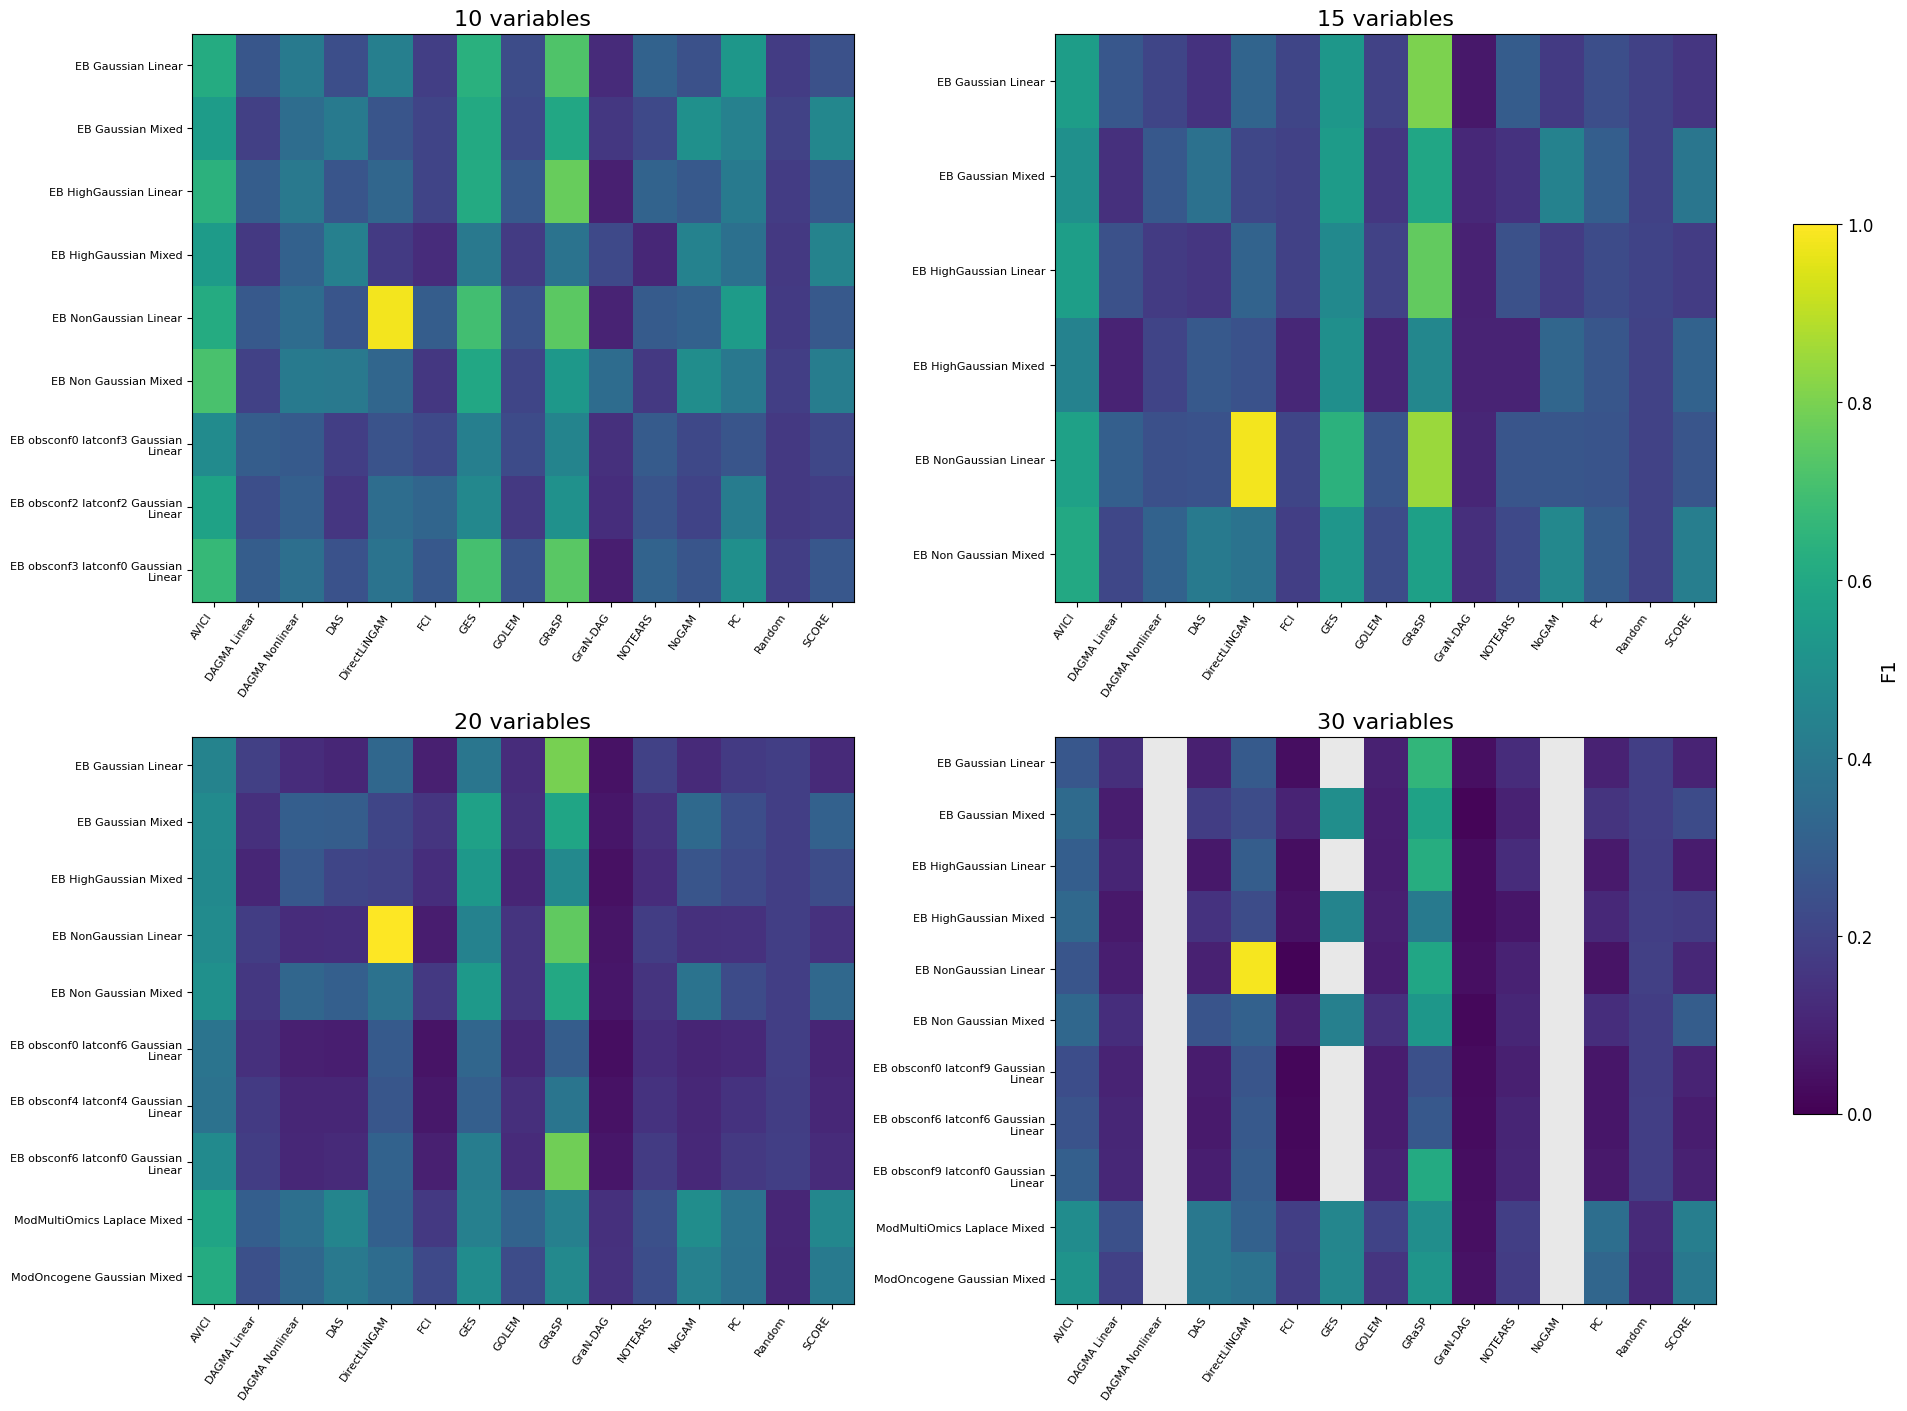

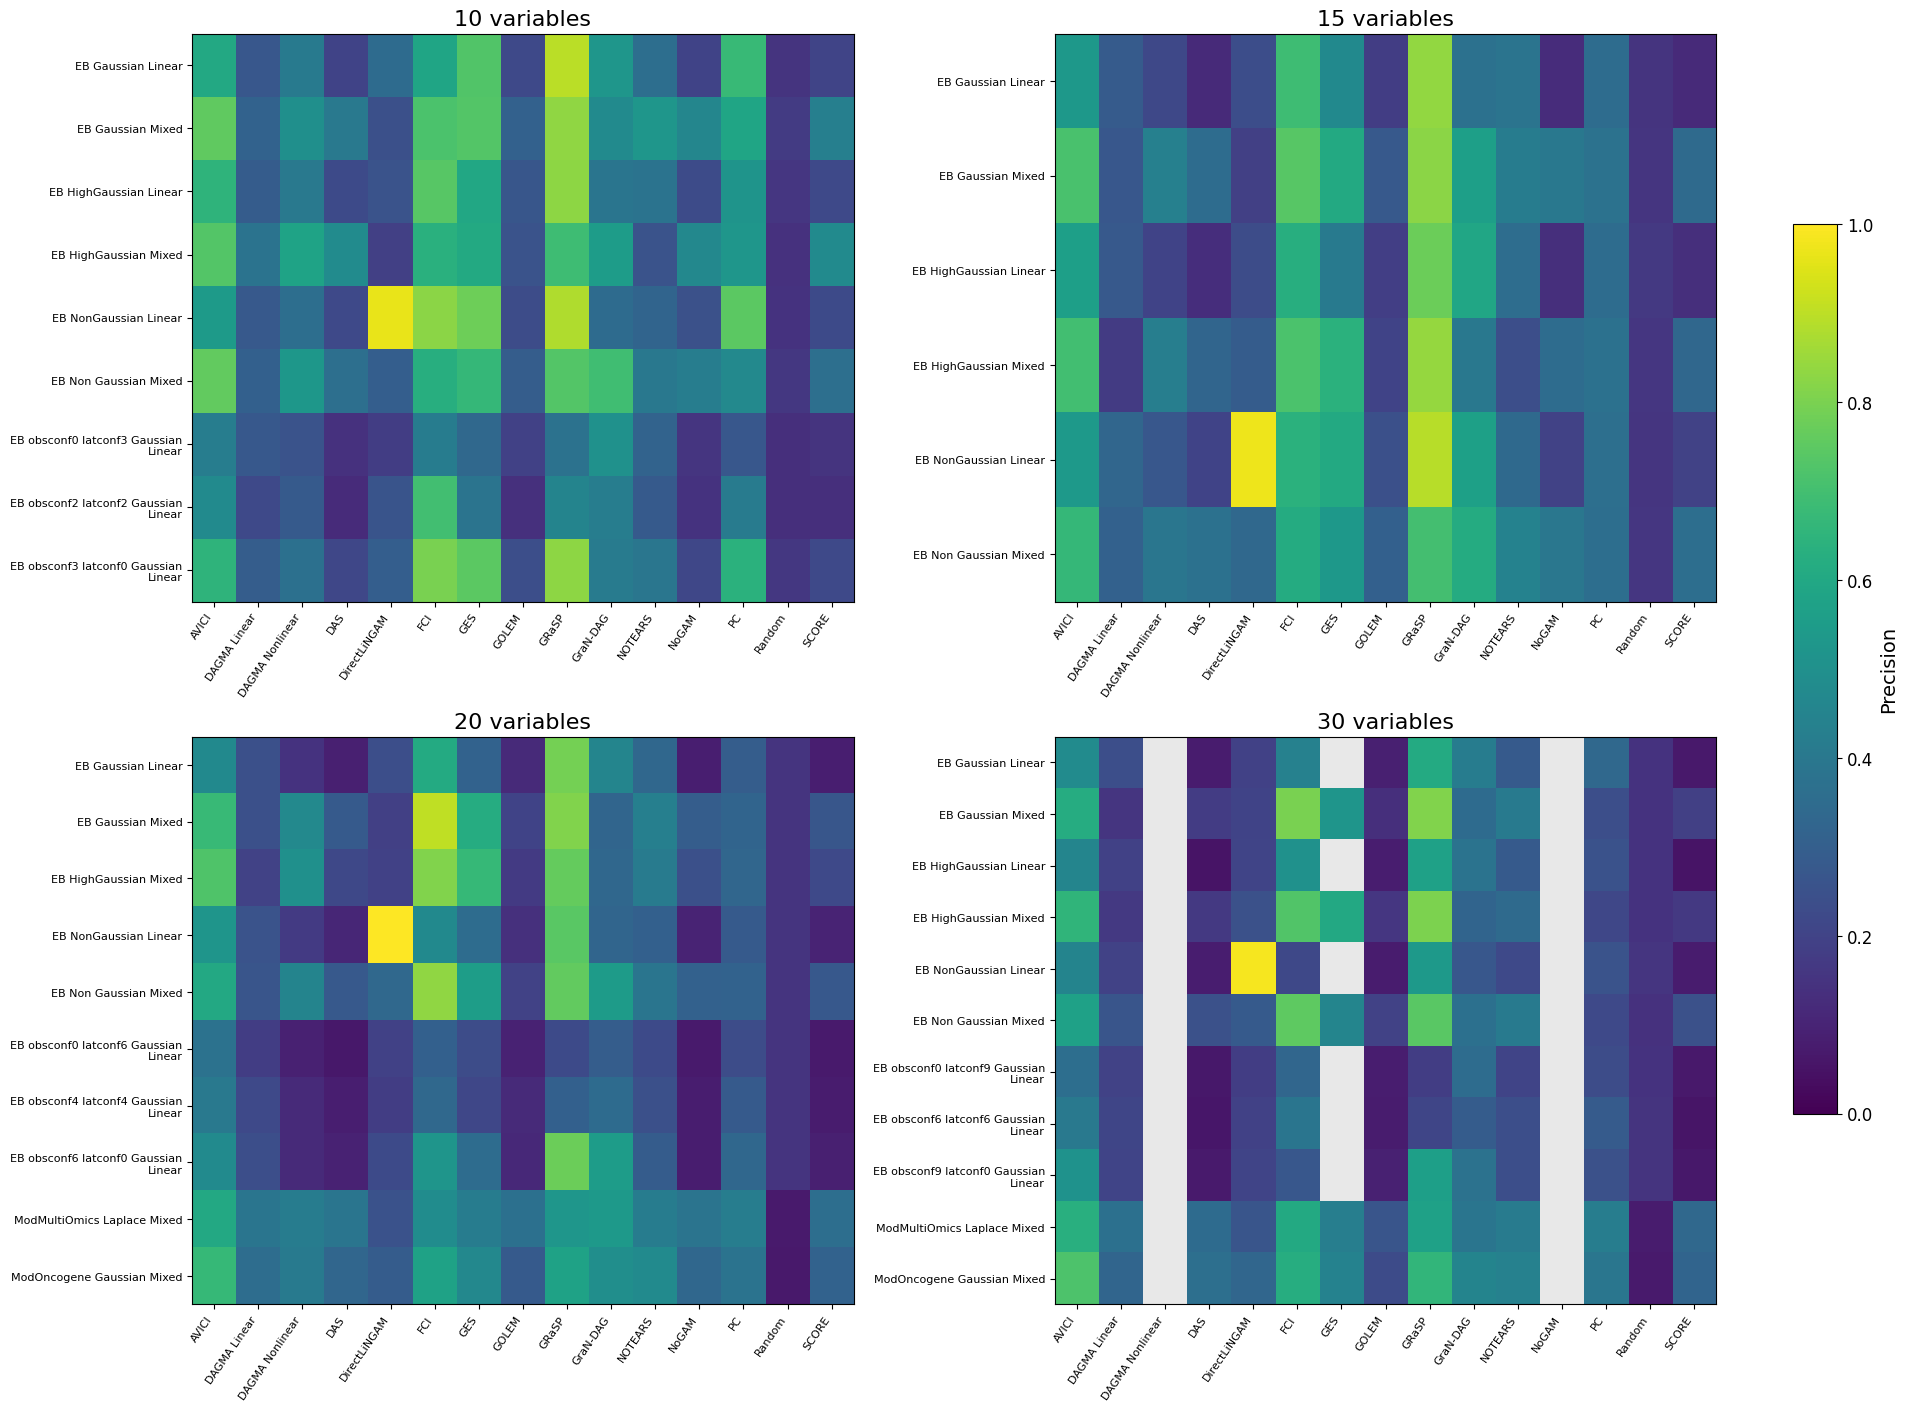

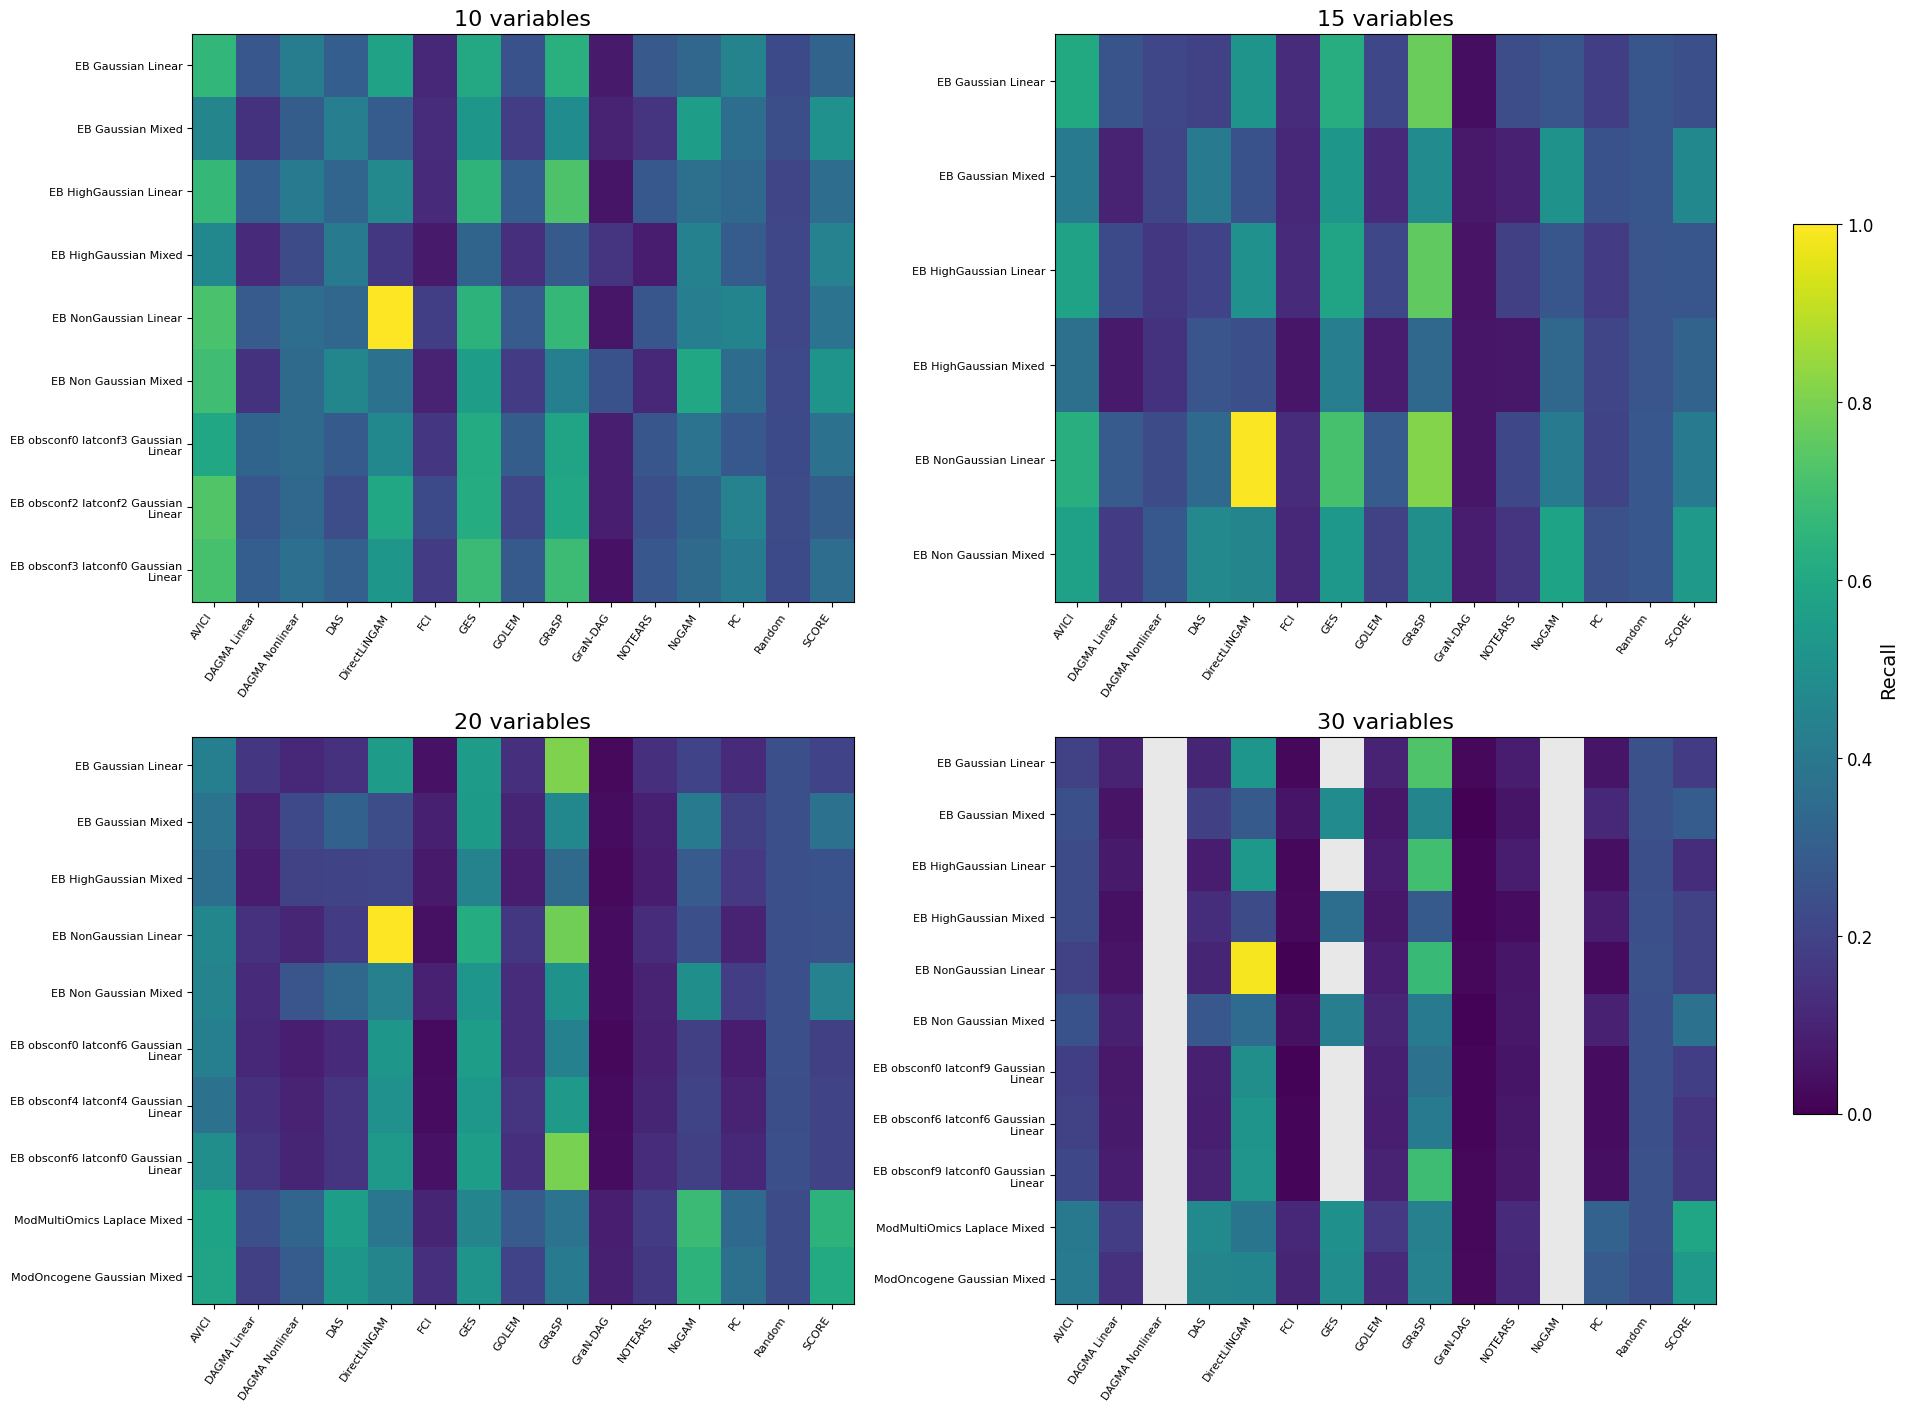

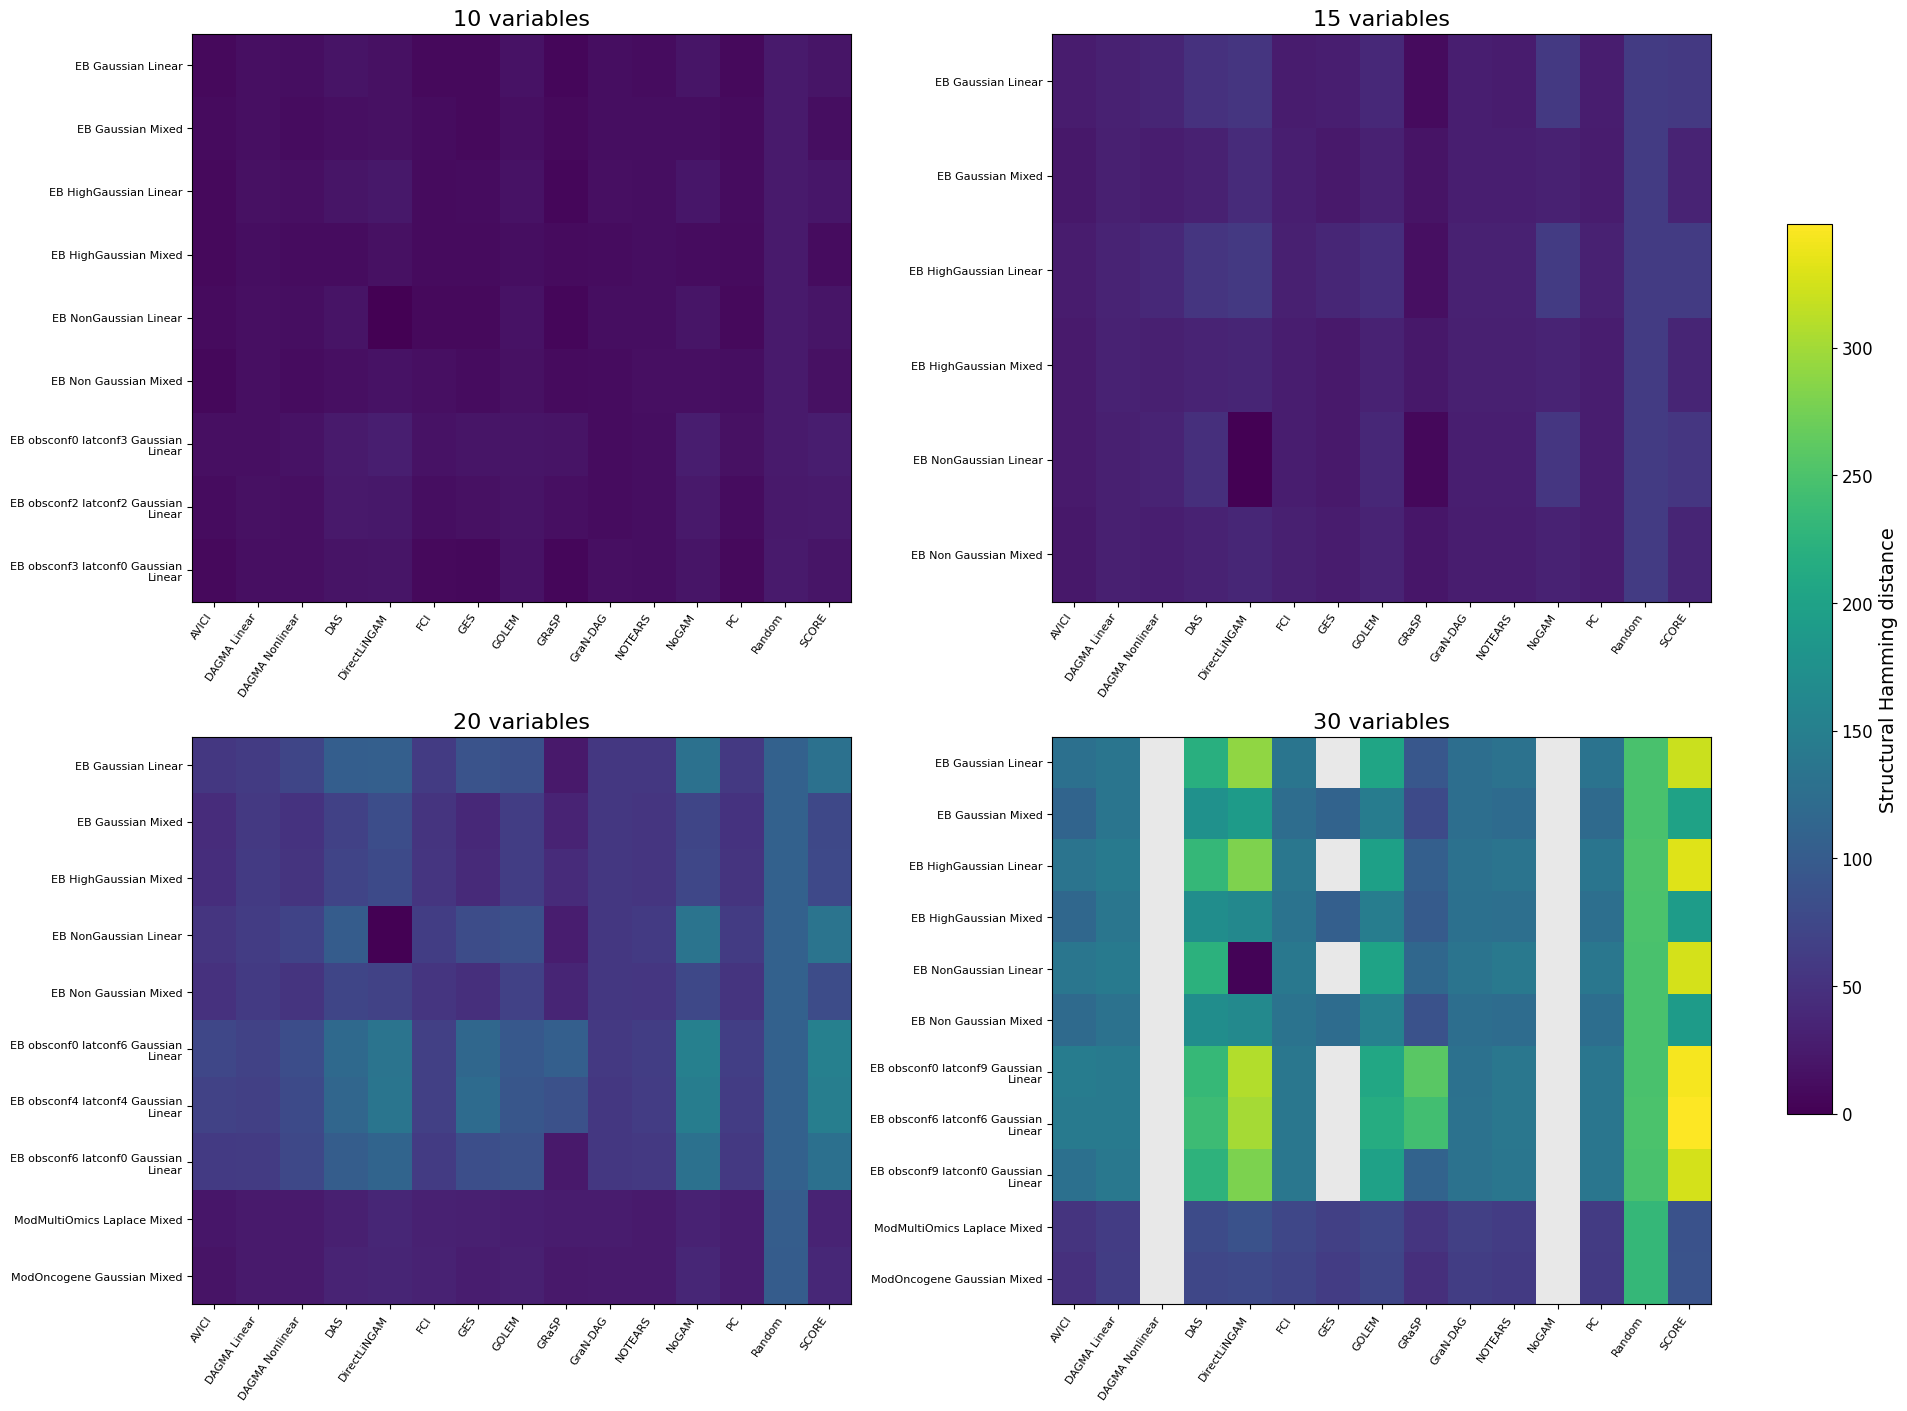

In [4]:
for metric, label in [("f1", "F1"), ("precision", "Precision"), ("recall", "Recall"), ("SHD", "Structural Hamming distance")]:
    plot_conditions(summary, f"{metric}_mean", label, f"{metric}_by_condition.pdf", bounded=metric != "SHD")
